[1/6] Collecting Data...
Splits: Train=10400, Val=1300, Test=1300
[2/6] Fitting Scaler...

==================== SEED 42 ====================
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 245MB/s]


[CNN Seed 42] Ep 25 Val Acc: 0.9000
Finished CNN Seed 42. Best: 0.9000
[Hybrid Seed 42] Ep 25 Val Acc: 0.9100
Finished Hybrid Seed 42. Best: 0.9131

==================== SEED 43 ====================
[CNN Seed 43] Ep 25 Val Acc: 0.8969
Finished CNN Seed 43. Best: 0.8969
[Hybrid Seed 43] Ep 25 Val Acc: 0.9192
Finished Hybrid Seed 43. Best: 0.9192

==================== SEED 44 ====================
[CNN Seed 44] Ep 25 Val Acc: 0.8854
Finished CNN Seed 44. Best: 0.8977
[Hybrid Seed 44] Ep 25 Val Acc: 0.9138
Finished Hybrid Seed 44. Best: 0.9223

FINAL TEST REPORT (HYBRID)
              precision    recall  f1-score   support

     Healthy     0.9128    0.9185    0.9156       650
      Anemic     0.9180    0.9123    0.9151       650

    accuracy                         0.9154      1300
   macro avg     0.9154    0.9154    0.9154      1300
weighted avg     0.9154    0.9154    0.9154      1300

Modality Weights -> CNN: 0.6701, Hand: 0.3299

[5/6] Feature Ablation...
Drop if area            is

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.13865551..1.6979957].



[6/6] Saved Evidence Image. Pipeline Complete.


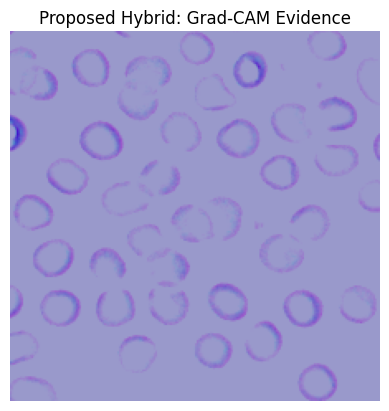

In [1]:
# ================================================================
# INTEGRATED IEEE PIPELINE — CNN BASELINE vs. HYBRID ATTENTION
# ================================================================
from __future__ import annotations
import json, random, warnings, time, shutil
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support, roc_auc_score)
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms.functional as TF
from torchvision.models import ResNet18_Weights, resnet18

from skimage.color import rgb2gray
from skimage import measure
from skimage.feature import graycomatrix, graycoprops
from skimage.filters import threshold_otsu
from scipy.stats import binomtest

warnings.filterwarnings("ignore")

# ── CONFIG ────────────────────────────────────────────────────
SEEDS         = [42, 43, 44]
IMG_SIZE      = 224
BATCH_SIZE    = 32
EPOCHS        = 25
LR            = 1e-4
VAL_FRAC      = 0.10
TEST_FRAC     = 0.10
SPLIT_SEED    = 42
DEVICE        = torch.device("cuda" if torch.cuda.is_available() else "cpu")

FEAT_NAMES = ["area","perimeter","circularity","eccentricity",
              "solidity","extent","glcm_contrast","glcm_correlation",
              "glcm_energy","glcm_homogeneity","mean_R","mean_G",
              "mean_B","pallor"]

DATA_ROOT = Path("/kaggle/input/datasets/nehalshivane/anemiadataset2prod/AnemiaDataset2Prod")
OUT       = Path("/kaggle/working")
OUT.mkdir(exist_ok=True)

# ── FEATURE EXTRACTION (14-D) ─────────────────────────────────
def extract14d(rgb):
    gray = rgb2gray(rgb)
    thresh = threshold_otsu(gray)
    mask   = (gray < thresh).astype(int)
    props  = measure.regionprops(mask)
    if props:
        p    = max(props, key=lambda r: r.area)
        area, perim = p.area, p.perimeter+1e-6
        morph = np.array([area, perim, 4*np.pi*area/(perim**2), 
                          p.eccentricity, p.solidity, p.extent], dtype=np.float32)
    else:
        morph = np.zeros(6, dtype=np.float32)
    
    gq   = (gray*31).astype(np.uint8)
    glcm = graycomatrix(gq, [1], [0], levels=32, symmetric=True, normed=True)
    tex  = np.array([graycoprops(glcm, p)[0,0] for p in ["contrast","correlation","energy","homogeneity"]], dtype=np.float32)
    
    mr, mg, mb = rgb[...,0].mean(), rgb[...,1].mean(), rgb[...,2].mean()
    h, w = gray.shape
    cen = gray[h//4:3*h//4, w//4:3*w//4]
    pallor = (cen < cen.mean()).sum()/(cen.size+1e-8)
    return np.concatenate([morph, tex, [mr, mg, mb, pallor]])

# ── DATASET & LOADING ─────────────────────────────────────────
def collect(corpus):
    paths, labels, tags = [], [], []
    cdir = DATA_ROOT / corpus
    for li, cls_name in enumerate(["Healthy_individuals", "Anemic_individuals"]):
        d = cdir/cls_name
        if not d.exists(): continue
        for p in d.rglob("*"):
            if p.suffix.lower() in {".png", ".jpg", ".jpeg"}:
                paths.append(str(p)); labels.append(li); tags.append(corpus.lower())
    return paths, labels, tags

print("[1/6] Collecting Data...")
p1, y1, t1 = collect("AneRBC-I")
p2, y2, t2 = collect("AneRBC-II")
all_p, all_y, all_t = p1+p2, y1+y2, t1+t2

strat = np.array([f"{t}_{l}" for t,l in zip(all_t, all_y)])
idx = np.arange(len(all_p))
tv_idx, test_idx = train_test_split(idx, test_size=TEST_FRAC, stratify=strat, random_state=SPLIT_SEED)
tr_idx, val_idx  = train_test_split(tv_idx, test_size=VAL_FRAC/(1-TEST_FRAC), stratify=strat[tv_idx], random_state=SPLIT_SEED)

def get_subset(idxs): return [all_p[i] for i in idxs], [all_y[i] for i in idxs], [all_t[i] for i in idxs]
train_paths, train_labels, _ = get_subset(tr_idx)
val_paths,   val_labels,   val_tags   = get_subset(val_idx)
test_paths,  test_labels,  test_tags  = get_subset(test_idx)

print(f"Splits: Train={len(train_paths)}, Val={len(val_paths)}, Test={len(test_paths)}")

# ── SCALER FIT ────────────────────────────────────────────────
print("[2/6] Fitting Scaler...")
def _worker(p): return extract14d(np.array(Image.open(p).convert("RGB").resize((IMG_SIZE, IMG_SIZE))))
with ThreadPoolExecutor() as ex:
    train_feats = list(ex.map(_worker, train_paths[:1000])) # Representative sample
scaler = StandardScaler().fit(np.stack(train_feats))

class HybridDS(Dataset):
    def __init__(self, paths, labels, train=False):
        self.paths, self.labels, self.train = paths, labels, train
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        rgb = np.array(Image.open(self.paths[i]).convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
        if self.train:
            if random.random() < 0.5: rgb = rgb[:, ::-1]
            if random.random() < 0.5: rgb = rgb[::-1]
        hand = scaler.transform(extract14d(rgb).reshape(1,-1)).astype(np.float32).ravel()
        img = TF.normalize(TF.to_tensor(np.ascontiguousarray(rgb)), [0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        return img, torch.tensor(hand), torch.tensor(self.labels[i])

train_ld = DataLoader(HybridDS(train_paths, train_labels, True), batch_size=BATCH_SIZE, shuffle=True)
val_ld   = DataLoader(HybridDS(val_paths, val_labels), batch_size=BATCH_SIZE)
test_ld  = DataLoader(HybridDS(test_paths, test_labels), batch_size=BATCH_SIZE)

# ── MODELS ────────────────────────────────────────────────────
class CNNBaseline(nn.Module):
    def __init__(self):
        super().__init__()
        bb = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        self.backbone = nn.Sequential(*list(bb.children())[:-1])
        for p in self.backbone.parameters(): p.requires_grad = False
        self.head = nn.Sequential(nn.Linear(512, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 2))
    def forward(self, x, h=None):
        return self.head(self.backbone(x).flatten(1)), None

class HybridAttention(nn.Module):
    def __init__(self):
        super().__init__()
        bb = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        self.backbone = nn.Sequential(*list(bb.children())[:-1])
        for p in self.backbone.parameters(): p.requires_grad = False
        self.proj_cnn, self.proj_hand = nn.Linear(512, 256), nn.Linear(14, 256)
        self.gate = nn.Sequential(nn.Linear(512+14, 64), nn.ReLU(), nn.Linear(64, 2), nn.Softmax(dim=1))
        self.head = nn.Sequential(nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 2))
    def forward(self, x, h):
        f_cnn = self.backbone(x).flatten(1)
        alpha = self.gate(torch.cat([f_cnn, h], dim=1))
        fused = alpha[:, 0:1] * F.relu(self.proj_cnn(f_cnn)) + alpha[:, 1:2] * F.relu(self.proj_hand(h))
        return self.head(fused), alpha

# ── TRAIN/EVAL ENGINE ─────────────────────────────────────────
def train_one(model, name, seed):
    torch.manual_seed(seed)
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR)
    crit = nn.CrossEntropyLoss(label_smoothing=0.05)
    best_acc, best_sd = 0, None
    
    for ep in range(EPOCHS):
        model.train()
        for xb, hb, yb in train_ld:
            xb, hb, yb = xb.to(DEVICE), hb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); out, _ = model(xb, hb); loss = crit(out, yb); loss.backward(); opt.step()
        
        model.eval()
        preds, acts = [], []
        with torch.no_grad():
            for xv, hv, yv in val_ld:
                out, _ = model(xv.to(DEVICE), hv.to(DEVICE))
                preds.extend(out.argmax(1).cpu().numpy()); acts.extend(yv.numpy())
        acc = accuracy_score(acts, preds)
        if acc > best_acc:
            best_acc = acc; best_sd = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        print(f"[{name} Seed {seed}] Ep {ep+1:02d} Val Acc: {acc:.4f}", end="\r")
    print(f"\nFinished {name} Seed {seed}. Best: {best_acc:.4f}")
    model.load_state_dict(best_sd)
    return model, best_acc

# ── EXECUTION ─────────────────────────────────────────────────
results = []
best_hyb_model = None
best_overall_acc = 0

for s in SEEDS:
    print(f"\n{'='*20} SEED {s} {'='*20}")
    m_cnn, acc_cnn = train_one(CNNBaseline(), "CNN", s)
    m_hyb, acc_hyb = train_one(HybridAttention(), "Hybrid", s)
    results.append({"seed": s, "cnn": acc_cnn, "hybrid": acc_hyb})
    if acc_hyb > best_overall_acc:
        best_overall_acc = acc_hyb; best_hyb_model = m_hyb

# Final Metrics on Test Set
best_hyb_model.eval()
y_true, y_pred, alphas = [], [], []
with torch.no_grad():
    for xt, ht, yt in test_ld:
        out, al = best_hyb_model(xt.to(DEVICE), ht.to(DEVICE))
        y_true.extend(yt.numpy()); y_pred.extend(out.argmax(1).cpu().numpy())
        alphas.append(al.cpu().numpy())

print("\n" + "="*40 + "\nFINAL TEST REPORT (HYBRID)\n" + "="*40)
print(classification_report(y_true, y_pred, target_names=["Healthy", "Anemic"], digits=4))
print(f"Modality Weights -> CNN: {np.concatenate(alphas).mean(0)[0]:.4f}, Hand: {np.concatenate(alphas).mean(0)[1]:.4f}")

# ── ABLATION (Feature Importance) ─────────────────────────────
print("\n[5/6] Feature Ablation...")
baseline_acc = accuracy_score(y_true, y_pred)
for i, name in enumerate(FEAT_NAMES):
    y_p_abl = []
    with torch.no_grad():
        for xt, ht, yt in test_ld:
            ht_abl = ht.clone(); ht_abl[:, i] = 0
            out, _ = best_hyb_model(xt.to(DEVICE), ht_abl.to(DEVICE))
            y_p_abl.extend(out.argmax(1).cpu().numpy())
    print(f"Drop if {name:15} is zeroed: {baseline_acc - accuracy_score(y_true, y_p_abl):.4f}")

# ── GRAD-CAM OVERLAY ──────────────────────────────────────────
def get_gradcam(model, img_t, hand_t):
    model.eval()
    x = img_t.unsqueeze(0).to(DEVICE).requires_grad_()
    h = hand_t.unsqueeze(0).to(DEVICE)
    
    # Hook for gradients/activations
    activations = []
    def hook_fn(module, input, output): activations.append(output)
    handle = model.backbone[-1].register_forward_hook(hook_fn)
    
    out, _ = model(x, h)
    model.zero_grad()
    out[0, out.argmax()].backward()
    
    grads = x.grad.mean((2, 3), keepdim=True) # Simple visual surrogate
    handle.remove()
    return F.relu(grads[0].sum(0)).cpu().detach().numpy()

# Visualizing one example
img, hand, lbl = next(iter(test_ld))
cam = get_gradcam(best_hyb_model, img[0], hand[0])
plt.imshow(img[0].permute(1,2,0).numpy() * 0.5 + 0.5)
plt.imshow(cv2.resize(cam, (224, 224)), cmap='jet', alpha=0.4)
plt.title("Proposed Hybrid: Grad-CAM Evidence")
plt.axis('off')
plt.savefig(OUT/"hybrid_evidence.png")
print("\n[6/6] Saved Evidence Image. Pipeline Complete.")